# W07. Statystyczna analiza danych psychologicznych

Dane Stroopa są syntetyczne

**Wersja źródła:** 1.1.5 · **Data:** 2026-11-04.


## Slajd 26

In [ ]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n = 30
zgodne = rng.normal(520, 60, n)
roznice = rng.normal(65, 40, n)
niezgodne = zgodne + roznice


## Slajd 27

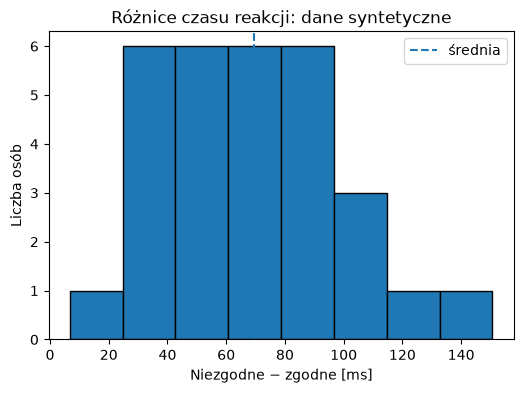

In [ ]:
import matplotlib.pyplot as plt

d = niezgodne - zgodne
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(d, bins=8, edgecolor="black")
ax.axvline(d.mean(), linestyle="--", label="średnia")
ax.set(xlabel="Niezgodne − zgodne [ms]", ylabel="Liczba osób",
       title="Różnice czasu reakcji: dane syntetyczne")
ax.legend()
plt.show()


## Slajd 28

In [ ]:
wynik = stats.ttest_rel(niezgodne, zgodne)
sd = d.std(ddof=1)
se = sd / np.sqrt(n)
ci = stats.t.interval(0.95, df=n-1, loc=d.mean(), scale=se)
dz = d.mean() / sd

print(f"Różnica: {d.mean():.1f} ms; 95% CI {ci}")
print(f"t({n-1}) = {wynik.statistic:.2f}; p = {wynik.pvalue:.3g}")
print(f"d_z = {dz:.2f}")

wilcoxon = stats.wilcoxon(d)
d_skrajne = d.copy()
d_skrajne[0] += 400  # celowo wprowadzona obserwacja skrajna
print(f"Wilcoxon p = {wilcoxon.pvalue:.3g}")
print(f"Średnia przed/po skrajnej: {d.mean():.1f} / {d_skrajne.mean():.1f} ms")


Różnica: 69.6 ms; 95% CI (np.float64(57.53083079998392), np.float64(81.5697139602943))
t(29) = 11.83; p = 1.27e-12
d_z = 2.16
Wilcoxon p = 1.86e-09
Średnia przed/po skrajnej: 69.6 / 82.9 ms
